In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style="whitegrid")

url = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"
df = pd.read_csv(url)
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce").fillna(0)
df["ChurnFlag"] = (df["Churn"] == "Yes").astype(int)
df["SeniorCitizen"] = df["SeniorCitizen"].map({0: "No", 1: "Yes"})
for c in ["OnlineSecurity", "TechSupport"]:
    df[c] = df[c].replace({"No internet service": "No"})
df["TenureGroup"] = pd.cut(df["tenure"], [-1, 12, 24, 48, 72], labels=["0-12", "13-24", "25-48", "49-72"])

Business problem: The telecom company is losing customers every month.
Key questions: How much revenue is being lost? Which customers leave most?
What can the company do to keep them?
Stakeholders: Retention team, marketing team, management.

In [2]:
total = len(df)
churned = df.ChurnFlag.sum()
mrr = df.MonthlyCharges.sum()
lost = df.loc[df.ChurnFlag == 1, "MonthlyCharges"].sum()

print("Total customers:", total)
print("Churned customers:", churned)
print("Churn rate: %.2f%%" % (churned / total * 100))
print("Total monthly revenue: %.0f" % mrr)
print("Monthly revenue lost to churn: %.0f (%.1f%%)" % (lost, lost / mrr * 100))
print("Annualised revenue lost: %.0f" % (lost * 12))
print("Avg monthly charge - churned: %.2f | stayed: %.2f" % (df[df.ChurnFlag == 1].MonthlyCharges.mean(), df[df.ChurnFlag == 0].MonthlyCharges.mean()))
print("Avg tenure (months) - churned: %.1f | stayed: %.1f" % (df[df.ChurnFlag == 1].tenure.mean(), df[df.ChurnFlag == 0].tenure.mean()))
print("Avg lifetime billing - churned: %.0f | stayed: %.0f" % (df[df.ChurnFlag == 1].TotalCharges.mean(), df[df.ChurnFlag == 0].TotalCharges.mean()))

Total customers: 7043
Churned customers: 1869
Churn rate: 26.54%
Total monthly revenue: 456117
Monthly revenue lost to churn: 139131 (30.5%)
Annualised revenue lost: 1669570
Avg monthly charge - churned: 74.44 | stayed: 61.27
Avg tenure (months) - churned: 18.0 | stayed: 37.6
Avg lifetime billing - churned: 1532 | stayed: 2550


In [3]:
for col in ["Contract", "InternetService", "PaymentMethod", "TenureGroup", "SeniorCitizen", "TechSupport", "OnlineSecurity"]:
    print(f"\nChurn % by {col}")
    print((df.groupby(col, observed=True).ChurnFlag.mean() * 100).round(1).sort_values(ascending=False))

mtm_share = df[(df.Contract == "Month-to-month")].ChurnFlag.sum() / churned * 100
print("\nShare of all churners on month-to-month contracts: %.1f%%" % mtm_share)


Churn % by Contract
Contract
Month-to-month    42.7
One year          11.3
Two year           2.8
Name: ChurnFlag, dtype: float64

Churn % by InternetService
InternetService
Fiber optic    41.9
DSL            19.0
No              7.4
Name: ChurnFlag, dtype: float64

Churn % by PaymentMethod
PaymentMethod
Electronic check             45.3
Mailed check                 19.1
Bank transfer (automatic)    16.7
Credit card (automatic)      15.2
Name: ChurnFlag, dtype: float64

Churn % by TenureGroup
TenureGroup
0-12     47.4
13-24    28.7
25-48    20.4
49-72     9.5
Name: ChurnFlag, dtype: float64

Churn % by SeniorCitizen
SeniorCitizen
Yes    41.7
No     23.6
Name: ChurnFlag, dtype: float64

Churn % by TechSupport
TechSupport
No     31.2
Yes    15.2
Name: ChurnFlag, dtype: float64

Churn % by OnlineSecurity
OnlineSecurity
No     31.3
Yes    14.6
Name: ChurnFlag, dtype: float64

Share of all churners on month-to-month contracts: 88.6%


In [4]:
risk1 = df[(df.Contract == "Month-to-month") & (df.tenure <= 12)]
print("Month-to-month, first year:", len(risk1), "customers | churn %.1f%%" % (risk1.ChurnFlag.mean() * 100),
      "| share of all churners %.1f%%" % (risk1.ChurnFlag.sum() / churned * 100))

risk2 = df[(df.Contract == "Month-to-month") & (df.InternetService == "Fiber optic") & (df.PaymentMethod == "Electronic check")]
print("Month-to-month + fiber + electronic check:", len(risk2), "customers | churn %.1f%%" % (risk2.ChurnFlag.mean() * 100))

Month-to-month, first year: 1994 customers | churn 51.4% | share of all churners 54.8%
Month-to-month + fiber + electronic check: 1307 customers | churn 60.4%


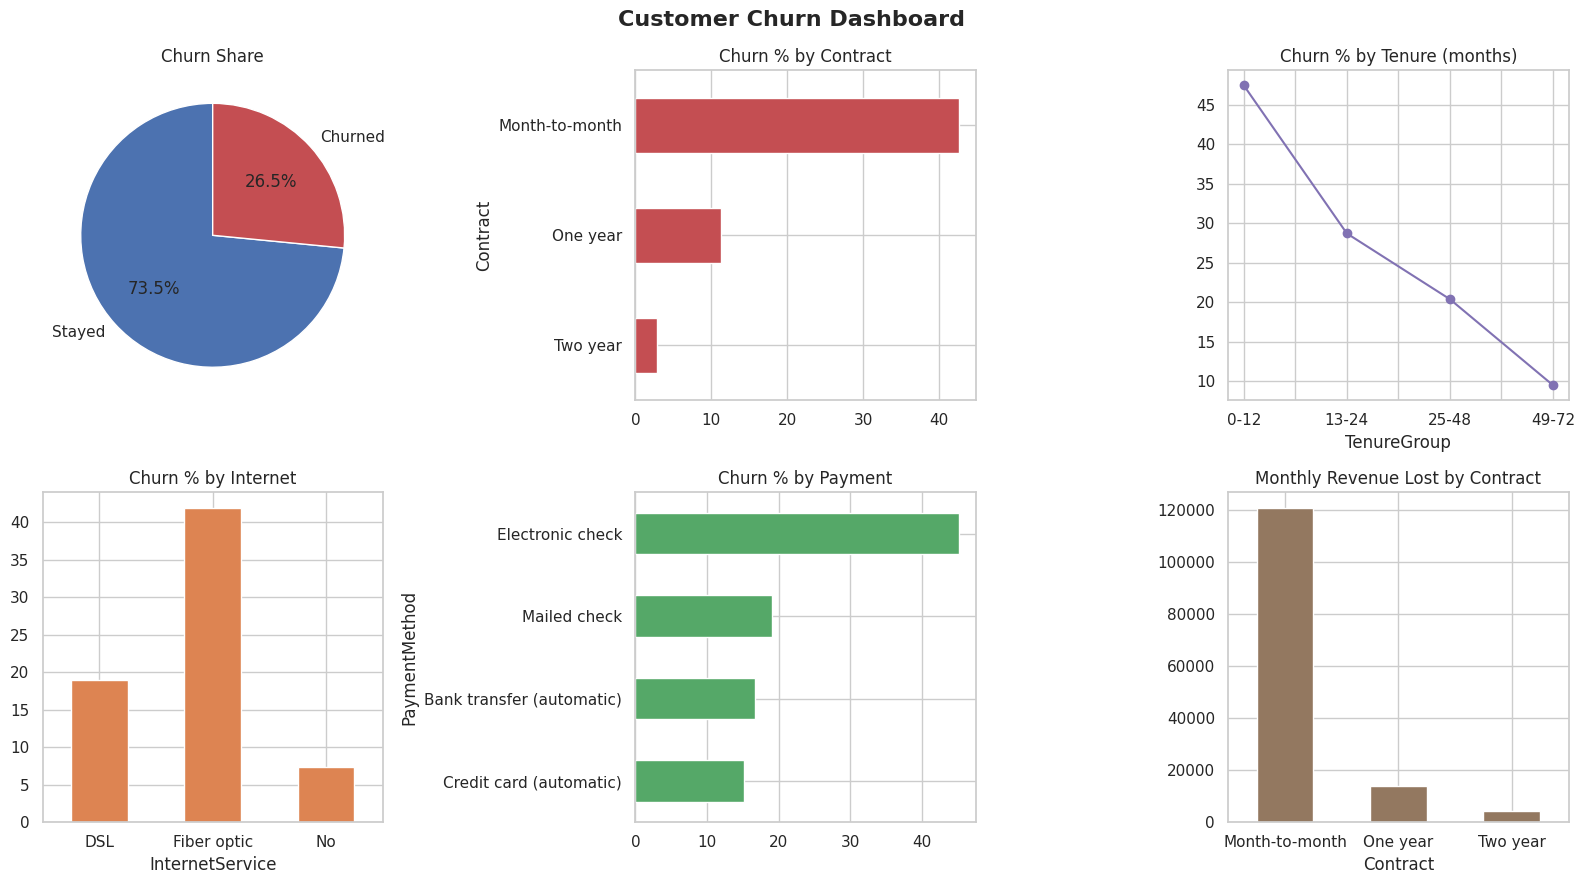

In [5]:
fig, ax = plt.subplots(2, 3, figsize=(16, 9))
fig.suptitle("Customer Churn Dashboard", fontsize=16, fontweight="bold")

sizes = [(df.ChurnFlag == 0).sum(), (df.ChurnFlag == 1).sum()]
ax[0,0].pie(sizes, labels=["Stayed", "Churned"], autopct="%1.1f%%", colors=["#4c72b0", "#c44e52"], startangle=90)
ax[0,0].set_title("Churn Share")

(df.groupby("Contract").ChurnFlag.mean() * 100).sort_values().plot.barh(ax=ax[0,1], color="#c44e52")
ax[0,1].set_title("Churn % by Contract")

(df.groupby("TenureGroup", observed=True).ChurnFlag.mean() * 100).plot(marker="o", ax=ax[0,2], color="#8172b3")
ax[0,2].set_title("Churn % by Tenure (months)")

(df.groupby("InternetService").ChurnFlag.mean() * 100).plot.bar(ax=ax[1,0], color="#dd8452")
ax[1,0].set_title("Churn % by Internet"); ax[1,0].tick_params(axis="x", rotation=0)

(df.groupby("PaymentMethod").ChurnFlag.mean() * 100).sort_values().plot.barh(ax=ax[1,1], color="#55a868")
ax[1,1].set_title("Churn % by Payment")

df[df.ChurnFlag == 1].groupby("Contract").MonthlyCharges.sum().plot.bar(ax=ax[1,2], color="#937860")
ax[1,2].set_title("Monthly Revenue Lost by Contract"); ax[1,2].tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()

In [6]:
mtm = df[df.Contract == "Month-to-month"]
moved = int(len(mtm) * 0.20)  # suppose 20% switch to a one-year plan
r_mtm = mtm.ChurnFlag.mean()
r_1y = df[df.Contract == "One year"].ChurnFlag.mean()
saved = moved * (r_mtm - r_1y)
avg_charge = mtm.MonthlyCharges.mean()

print("Customers moved to one-year plans:", moved)
print("Customers saved from churning: %.0f" % saved)
print("Monthly revenue protected: %.0f" % (saved * avg_charge))
print("Annual revenue protected: %.0f" % (saved * avg_charge * 12))
print("New overall churn rate: %.2f%% (was %.2f%%)" % ((churned - saved) / total * 100, churned / total * 100))

Customers moved to one-year plans: 775
Customers saved from churning: 244
Monthly revenue protected: 16179
Annual revenue protected: 194145
New overall churn rate: 23.08% (was 26.54%)
